In [1]:

# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    GlobalAveragePooling1D,
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("TensorFlow version:", tf.__version__)
print("All libraries imported successfully!")


TensorFlow version: 2.21.0
All libraries imported successfully!


In [2]:

# Load IMDB movie review dataset

max_words = 20000
max_length = 200

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=max_words
)

print("Dataset loaded successfully!")

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Vocabulary size:", max_words)

print("\nSample labels:")
print(y_train[:10])

print("\nPositive reviews:", np.sum(y_train == 1))
print("Negative reviews:", np.sum(y_train == 0))


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset loaded successfully!
Training samples: 25000
Testing samples: 25000
Vocabulary size: 20000

Sample labels:
[1 0 0 1 0 0 1 0 1 0]

Positive reviews: 12500
Negative reviews: 12500


In [3]:

# Pad sequences to equal length

X_train = pad_sequences(
    X_train,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    X_test,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Text preprocessing completed!")

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nSample vectorized review:")
print(X_train[0][:30])


Text preprocessing completed!
Training shape: (25000, 200)
Testing shape: (25000, 200)

Sample vectorized review:
[   1   14   22   16   43  530  973 1622 1385   65  458 4468   66 3941
    4  173   36  256    5   25  100   43  838  112   50  670    2    9
   35  480]


In [4]:

# Split training data into training and validation sets

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nData splitting completed!")


Training samples: 20000
Validation samples: 5000
Testing samples: 25000

Data splitting completed!


In [5]:

# Build NLP deep learning model

model = Sequential([
    Embedding(
        input_dim=max_words,
        output_dim=64,
        mask_zero=True,
        input_length=max_length
    ),

    GlobalAveragePooling1D(),

    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.5),

    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

# Compile model

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture

model.summary()

print("Neural network created successfully!")


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Neural network created successfully!


In [6]:

# Configure Early Stopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

print("Early Stopping configured successfully!")


Early Stopping configured successfully!


In [7]:

# Train the deep learning model

history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping],
    verbose=1
)

print("Model training completed!")


Epoch 1/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - accuracy: 0.7988 - loss: 0.4376 - val_accuracy: 0.7822 - val_loss: 0.6050
Epoch 2/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.9129 - loss: 0.2218 - val_accuracy: 0.8196 - val_loss: 0.4006
Epoch 3/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.9414 - loss: 0.1560 - val_accuracy: 0.8256 - val_loss: 0.4966
Epoch 4/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.9584 - loss: 0.1123 - val_accuracy: 0.8416 - val_loss: 0.5170
Epoch 5/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9672 - loss: 0.0891 - val_accuracy: 0.8270 - val_loss: 0.5971
Model training completed!


In [8]:

# Evaluate model on unseen test data

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nMODEL EVALUATION")
print("----------------------")

print("Test Loss:", round(test_loss, 4))

print(
    "Test Accuracy:",
    round(test_accuracy * 100, 2),
    "%"
)


782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8028 - loss: 0.4181

MODEL EVALUATION
----------------------
Test Loss: 0.4181
Test Accuracy: 80.28 %


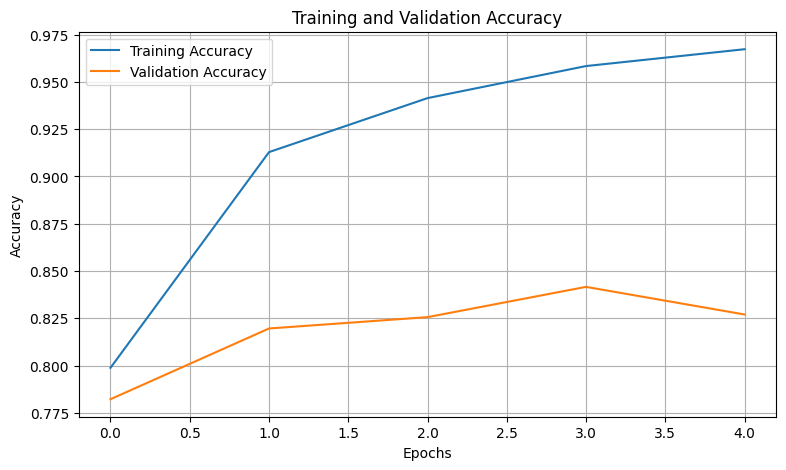

In [9]:

# Plot accuracy curves

plt.figure(figsize=(9, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.grid()

plt.show()


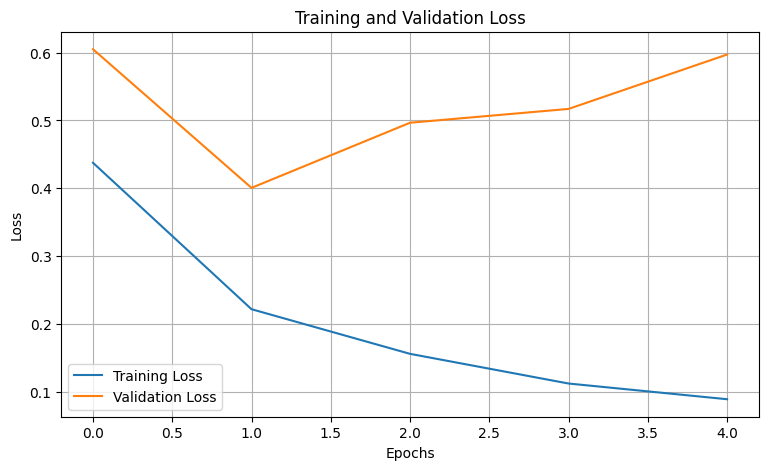

In [10]:

# Plot loss curves

plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training and Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid()

plt.show()


782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step
CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.92      0.66      0.77     12500
    Positive       0.74      0.94      0.83     12500

    accuracy                           0.80     25000
   macro avg       0.83      0.80      0.80     25000
weighted avg       0.83      0.80      0.80     25000



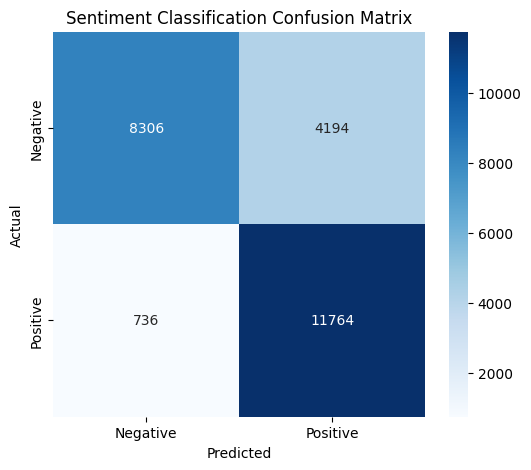

In [11]:

# Generate predictions

y_prob = model.predict(X_test)

y_pred = (y_prob >= 0.5).astype(int).flatten()

# Classification report

print("CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"]
    )
)

# Confusion matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Sentiment Classification Confusion Matrix")

plt.show()


In [12]:

# Convert new text into numerical sequences

word_index = imdb.get_word_index()

def encode_review(text):

    words = text.lower().split()

    sequence = [1]

    for word in words:

        word = "".join(
            ch for ch in word if ch.isalnum()
        )

        if word:
            index = word_index.get(word, 2) + 3

            if index >= max_words:
                index = 2

            sequence.append(index)

    return pad_sequences(
        [sequence],
        maxlen=max_length,
        padding="post",
        truncating="post"
    )


# Function to predict sentiment

def predict_sentiment(review):

    encoded = encode_review(review)

    probability = model.predict(
        encoded,
        verbose=0
    )[0][0]

    sentiment = (
        "Positive" if probability >= 0.5
        else "Negative"
    )

    confidence = (
        probability if probability >= 0.5
        else 1 - probability
    )

    print("\nReview:", review)
    print("Predicted Sentiment:", sentiment)
    print("Confidence:", round(confidence * 100, 2), "%")


# Test sample reviews

predict_sentiment(
    "This movie was amazing and the acting was excellent"
)

predict_sentiment(
    "This movie was boring and the story was terrible"
)

predict_sentiment(
    "I really enjoyed this wonderful and entertaining film"
)


1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Review: This movie was amazing and the acting was excellent
Predicted Sentiment: Positive
Confidence: 100.0 %

Review: This movie was boring and the story was terrible
Predicted Sentiment: Negative
Confidence: 100.0 %

Review: I really enjoyed this wonderful and entertaining film
Predicted Sentiment: Positive
Confidence: 100.0 %


In [13]:

# Save trained deep learning model

model.save("sentiment_analysis_model.keras")

print("Model saved successfully!")

# Load saved model

loaded_model = tf.keras.models.load_model(
    "sentiment_analysis_model.keras"
)

print("Saved model loaded successfully!")


Model saved successfully!
Saved model loaded successfully!


In [14]:

# Final project summary

print("=" * 50)
print("DEEP LEARNING NLP PROJECT COMPLETED")
print("=" * 50)

print("Dataset: IMDB Movie Reviews")
print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))

print(
    "Test Accuracy:",
    round(test_accuracy * 100, 2),
    "%"
)

print("\nCompleted Tasks:")

print("1. Dataset Loading")
print("2. Text Tokenization and Vectorization")
print("3. Text Padding")
print("4. Neural Network Construction")
print("5. Dropout and Batch Normalization")
print("6. Early Stopping")
print("7. Model Training and Validation")
print("8. Training Curves Visualization")
print("9. Classification Evaluation")
print("10. Unseen Text Prediction")
print("11. Model Saving")

print("\nPROJECT COMPLETED SUCCESSFULLY!")


DEEP LEARNING NLP PROJECT COMPLETED
Dataset: IMDB Movie Reviews
Training Samples: 20000
Validation Samples: 5000
Testing Samples: 25000
Test Accuracy: 80.28 %

Completed Tasks:
1. Dataset Loading
2. Text Tokenization and Vectorization
3. Text Padding
4. Neural Network Construction
5. Dropout and Batch Normalization
6. Early Stopping
7. Model Training and Validation
8. Training Curves Visualization
9. Classification Evaluation
10. Unseen Text Prediction
11. Model Saving

PROJECT COMPLETED SUCCESSFULLY!


In [15]:

# Download trained model

from google.colab import files

files.download("sentiment_analysis_model.keras")

print("Model downloaded successfully!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model downloaded successfully!
